In [1]:
import os

workdir = '/vast/ai_projects/Papenfuss_SVEnsemble2/model'
os.chdir(workdir)
os.getcwd()

import copy
import importlib

import numpy as np
import pandas as pd
import matplotlib as mpl
import pyranges as pr
import sklearn

from sklearn.ensemble import RandomForestClassifier as RF
import sklearn.model_selection as skm
from sklearn.metrics import confusion_matrix

In [2]:
pd.set_option('display.max_columns', None)

In [3]:
import os

job_id = os.environ.get('SLURM_JOB_ID')
if job_id:
    print(f"Running as SLURM job {job_id}")
else:
    print("Not running as a SLURM job")


Running as SLURM job 19274039


In [4]:
# The idea:
# 1. Split the dataset into a validation and training dataset
# 2. Train a non-traditional classifier (on the training dataset)
# 3. Estimate label frequency by applying the nontraditional classifier
# on the validation dataset and calculate class prior
# 4. Use class prior for weighing the training dataset and train again
# In Du Plessis paper there is a risk function - see nalysis of Learning from Positive and Unlabeled Data

In [5]:
# df_path = 'saved/gridss_overlaps.tsv'
# callset_overlapped_df = pd.read_csv(df_path, sep='\t', index_col='ID')

df_path = 'saved/gridss.overlapped_bps.csv'
callset_overlapped_df = pd.read_csv(df_path, index_col='INFO_EVENT')
# callset_overlapped_df = callset_overlapped_df.loc[:, ~(callset_overlapped_df.dtypes == 'object')]


In [6]:
callset_overlapped_df

,POS_bnd1,REF_bnd1,QUAL_bnd1,FORMAT_ANRP_bnd1,FORMAT_ANRPQ_bnd1,FORMAT_ANSR_bnd1,FORMAT_ANSRQ_bnd1,FORMAT_ASQ_bnd1,FORMAT_ASRP_bnd1,FORMAT_ASSR,FORMAT_BQ_bnd1,FORMAT_BSC_bnd1,FORMAT_BSCQ_bnd1,FORMAT_BUM_bnd1,FORMAT_BUMQ_bnd1,FORMAT_BVF_bnd1,FORMAT_CASQ_bnd1,FORMAT_IC,FORMAT_IQ,FORMAT_QUAL_bnd1,FORMAT_RASQ_bnd1,FORMAT_REF_bnd1,FORMAT_REFPAIR_bnd1,FORMAT_RP,FORMAT_RPQ,FORMAT_SR,FORMAT_SRQ,FORMAT_VF_bnd1,INFO_ANRP_bnd1,INFO_ANRPQ_bnd1,INFO_ANSR_bnd1,INFO_ANSRQ_bnd1,INFO_AS_bnd1,INFO_ASQ_bnd1,INFO_ASRP_bnd1,INFO_ASSR,INFO_BMQ_bnd1,INFO_BMQN_bnd1,INFO_BMQX_bnd1,INFO_BQ_bnd1,INFO_BSC_bnd1,INFO_BSCQ_bnd1,INFO_BUM_bnd1,INFO_BUMQ_bnd1,INFO_BVF_bnd1,INFO_CAS_bnd1,INFO_CASQ_bnd1,INFO_CQ,INFO_IC,INFO_IQ,INFO_MQ_bnd1,INFO_MQN,INFO_MQX,INFO_RAS_bnd1,INFO_RASQ_bnd1,INFO_REF_bnd1,INFO_REFPAIR_bnd1,INFO_RP,INFO_RPQ,INFO_SB_bnd1,INFO_SR,INFO_SRQ,INFO_VF_bnd1,INFO_CIPOS_l_bnd1,INFO_CIPOS_r_bnd1,bnd_pos_encoding_bnd1,POS_bnd2,REF_bnd2,QUAL_bnd2,FORMAT_ANRP_bnd2,FORMAT_ANRPQ_bnd2,FORMAT_ANSR_bnd2,FORMAT_ANSRQ_bnd2,FORMAT_ASQ_bnd2,FORMAT_ASRP_bnd2,FORMAT_BQ_bnd2,FORMAT_BSC_bnd2,FORMAT_BSCQ_bnd2,FORMAT_BUM_bnd2,FORMAT_BUMQ_bnd2,FORMAT_BVF_bnd2,FORMAT_CASQ_bnd2,FORMAT_QUAL_bnd2,FORMAT_RASQ_bnd2,FORMAT_REF_bnd2,FORMAT_REFPAIR_bnd2,FORMAT_VF_bnd2,INFO_ANRP_bnd2,INFO_ANRPQ_bnd2,INFO_ANSR_bnd2,INFO_ANSRQ_bnd2,INFO_AS_bnd2,INFO_ASQ_bnd2,INFO_ASRP_bnd2,INFO_BMQ_bnd2,INFO_BMQN_bnd2,INFO_BMQX_bnd2,INFO_BQ_bnd2,INFO_BSC_bnd2,INFO_BSCQ_bnd2,INFO_BUM_bnd2,INFO_BUMQ_bnd2,INFO_BVF_bnd2,INFO_CAS_bnd2,INFO_CASQ_bnd2,INFO_MQ_bnd2,INFO_RAS_bnd2,INFO_RASQ_bnd2,INFO_REF_bnd2,INFO_REFPAIR_bnd2,INFO_SB_bnd2,INFO_VF_bnd2,INFO_CIPOS_l_bnd2,INFO_CIPOS_r_bnd2,bnd_pos_encoding_bnd2,bndtype,is_in_training
INFO_EVENT,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
gridss0bb_1063,6558931,G,250.74,0,0.00,0,0.00,159.80,6,4,37.96,1,15.81,1,22.15,2,0.0,0,0.0,250.74,0.00,36,32,6,90.94,0,0.00,10,0,0.00,0,0.00,1,159.80,6,4,60.00,60.0,60.0,37.96,1,15.81,1,22.15,2,0,0.0,250.74,0,0.0,57.63,36.0,60.0,1,0.00,36,32,6,90.94,0.000000,0,0.00,10,-16,17,4,6559638,G,250.74,0,0.00,0,0.00,0.00,6,39.27,1,17.12,1,22.15,1,0.0,250.74,159.80,40,24,10,0,0.00,0,0.00,1,0.00,6,57.50,56.0,59.0,39.27,1,17.12,1,22.15,1,0,0.0,57.63,1,159.80,40,24,0.000000,10,-17,16,4,44,False
gridss0bb_1096,6705183,T,137.01,0,0.00,6,137.01,0.00,0,0,66.15,0,0.00,3,66.15,1,0.0,0,0.0,137.01,0.00,52,26,0,0.00,6,137.01,6,0,0.00,6,137.01,0,0.00,0,0,34.67,22.0,60.0,66.15,0,0.00,3,66.15,1,0,0.0,137.01,0,0.0,27.33,21.0,37.0,0,0.00,52,26,0,0.00,0.666667,6,137.01,6,-5,5,4,130418562,A,137.01,0,0.00,6,137.01,0.00,0,0.00,0,0.00,0,0.00,0,0.0,137.01,0.00,47,27,6,0,0.00,6,137.01,0,0.00,0,0.00,0.0,0.0,0.00,0,0.00,0,0.00,0,0,0.0,27.33,0,0.00,47,27,0.333333,6,-5,5,4,44,False
gridss0bb_1098,6709788,T,227.71,0,0.00,1,23.16,0.00,0,10,42.77,2,42.77,0,0.00,2,0.0,0,0.0,227.71,204.55,53,14,0,0.00,1,23.16,10,0,0.00,1,23.16,0,0.00,0,10,60.00,60.0,60.0,42.77,2,42.77,0,0.00,2,0,0.0,227.71,0,0.0,54.50,39.0,60.0,1,204.55,53,14,0,0.00,0.076923,1,23.16,10,-7,7,4,131665332,A,227.71,0,0.00,0,0.00,204.55,0,204.69,9,182.55,1,22.15,2,0.0,227.71,0.00,39,30,10,0,0.00,0,0.00,1,204.55,0,58.00,40.0,60.0,204.69,9,182.55,1,22.15,2,0,0.0,54.50,0,0.00,39,30,0.100000,10,-7,7,4,44,False
gridss0bb_1113,6740259,T,292.34,0,0.00,0,0.00,272.96,0,12,158.80,6,158.80,0,0.00,2,0.0,0,0.0,292.34,0.00,48,38,0,0.00,1,19.38,12,0,0.00,0,0.00,1,272.96,0,12,46.67,40.0,60.0,158.80,6,158.80,0,0.00,2,0,0.0,292.34,0,0.0,60.00,60.0,60.0,0,0.00,48,38,0,0.00,0.473684,1,19.38,12,-7,7,4,16413723,A,292.34,0,0.00,1,19.38,0.00,0,48.92,1,26.77,1,22.15,2,0.0,292.34,272.96,38,29,12,0,0.00,1,19.38,0,0.00,0,50.00,40.0,60.0,48.92,1,26.77,1,22.15,2,0,0.0,60.00,1,272.96,38,29,0.571429,12,-7,7,4,44,False
gridss0bb_1266,7392267,T,127.12,0,0.00,0,0.00,108.59,0,6,142.20,6,120.05,1,22.15,2,0.0,0,0.0,127.12,0.00,45,36,0,0.00,1,18.53,6,0,0.00,0,0.00,1,108.59,0,6,52.43,30.0,60.0,142.20,6,120.05,1,22.15,2,0,0.0,127.12,0,0.0,60.00,60.0,60.0,0,0.00,45,36,0,0

In [7]:
def get_overlapped_xy(overlapped_df, match_col='is_in_training'):
    overlapped_df_copy = overlapped_df.copy().rename(columns={match_col: 'ref_matched'})
    X = pd.get_dummies(overlapped_df_copy.drop(columns=['ref_matched']))
    # Drop columns with only 1 unique value
    nunique = X.nunique()
    constant_cols = nunique[nunique == 1].index
    X = X.drop(columns=constant_cols)
    y = overlapped_df_copy['ref_matched']
    return X, y

X, y = get_overlapped_xy(callset_overlapped_df)
X_train, X_val, y_train, y_val = skm.train_test_split(X, y, train_size=0.8, random_state=0)

In [8]:
RF_nontrad = RF(max_features=int(np.sqrt(X.shape[1])), random_state=0, n_estimators=500)
RF_nontrad_fit = RF_nontrad.fit(X_train, y_train)
y_nontrad = RF_nontrad_fit.predict(X_val)

label_freq = sum(y_nontrad & y_val) / sum(y_val)
label_prob = sum(y) / len(y)
clpr = label_prob / label_freq

In [9]:
# Weight for True: 2 * clpr / label_prob
# Weight for False: 1 / (1 - label_prob)

In [10]:
# Define class weights based on label probability and class prior ratio
# Weight for negative class (0) is inversely proportional to probability of negative examples
# Weight for positive class (1) accounts for class prior ratio and label probability
weight_dict = {
    0: 1 / (1 - label_prob),  # Weight for negative class
    1: 2 * clpr / label_prob  # Weight for positive class
}

# Initialize Random Forest classifier with:
# - Number of features per split: sqrt(total features) 
# - Fixed random seed for reproducibility
# - Class weights from above
# - 500 trees in the forest
RF_duplessis = RF(
    max_features=int(np.sqrt(X.shape[1])),
    random_state=0,
    class_weight=weight_dict,
    n_estimators=500
)

# Train the classifier on training data
RF_duplessis_fit = RF_duplessis.fit(X_train, y_train)

# Get probability predictions for all examples
# Extract probability of positive class ([:,1])
y_duplessis = RF_duplessis_fit.predict_proba(X)[:,1]

# Save predictions to CSV file
# pd.Series(y_duplessis).to_csv('saved/y_duplessis.csv')
pd.Series(y_duplessis).to_csv('saved/y_duplessis_bps.csv')

Elapsed time to compute the importances: 0.415 seconds


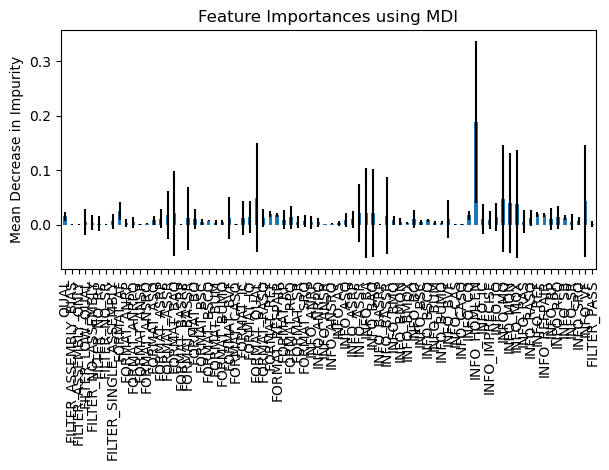

In [33]:
calc_feature_importance = True

if calc_feature_importance:
    import time
    import matplotlib.pyplot as plt
    # Calculate feature importances
    start_time = time.time()
    importances = RF_duplessis_fit.feature_importances_
    std = np.std([
        tree.feature_importances_ 
        for tree in RF_duplessis_fit.estimators_
    ], axis=0)
    elapsed_time = time.time() - start_time

    print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

    # Create visualization
    forest_importances = pd.Series(importances, index=X.columns)

    fig, ax = plt.subplots()
    forest_importances.plot.bar(yerr=std, ax=ax)
    ax.set_title("Feature Importances using MDI")
    ax.set_ylabel("Mean Decrease in Impurity")
    fig.tight_layout()

In [11]:
from sklearn.inspection import permutation_importance
import time

start_time = time.time()
result = permutation_importance(
    RF_duplessis_fit, X_val, y_val, n_repeats=10, random_state=42, n_jobs=2
)
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

forest_importances = pd.Series(result.importances_mean, index=X.columns)

/stornext/Home/data/allstaff/s/shikov.v/.local/share/mamba/envs/SVEnsemble2/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Elapsed time to compute the importances: 2387.336 seconds


NameError: name 'plt' is not defined

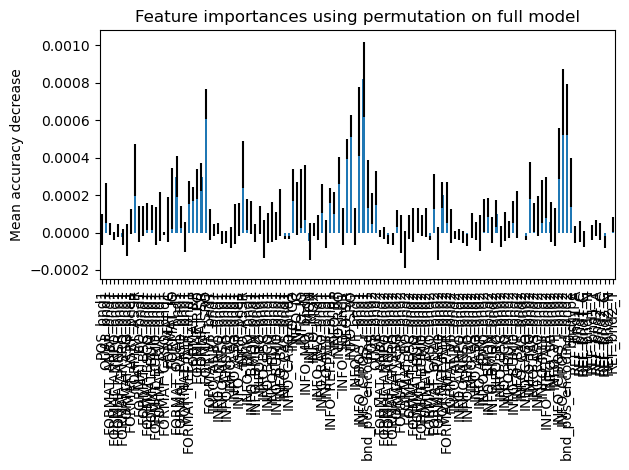

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
forest_importances.plot(yerr=result.importances_std, ax=ax, kind='bar')
ax.set_title("Feature importances using permutation on full model")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()

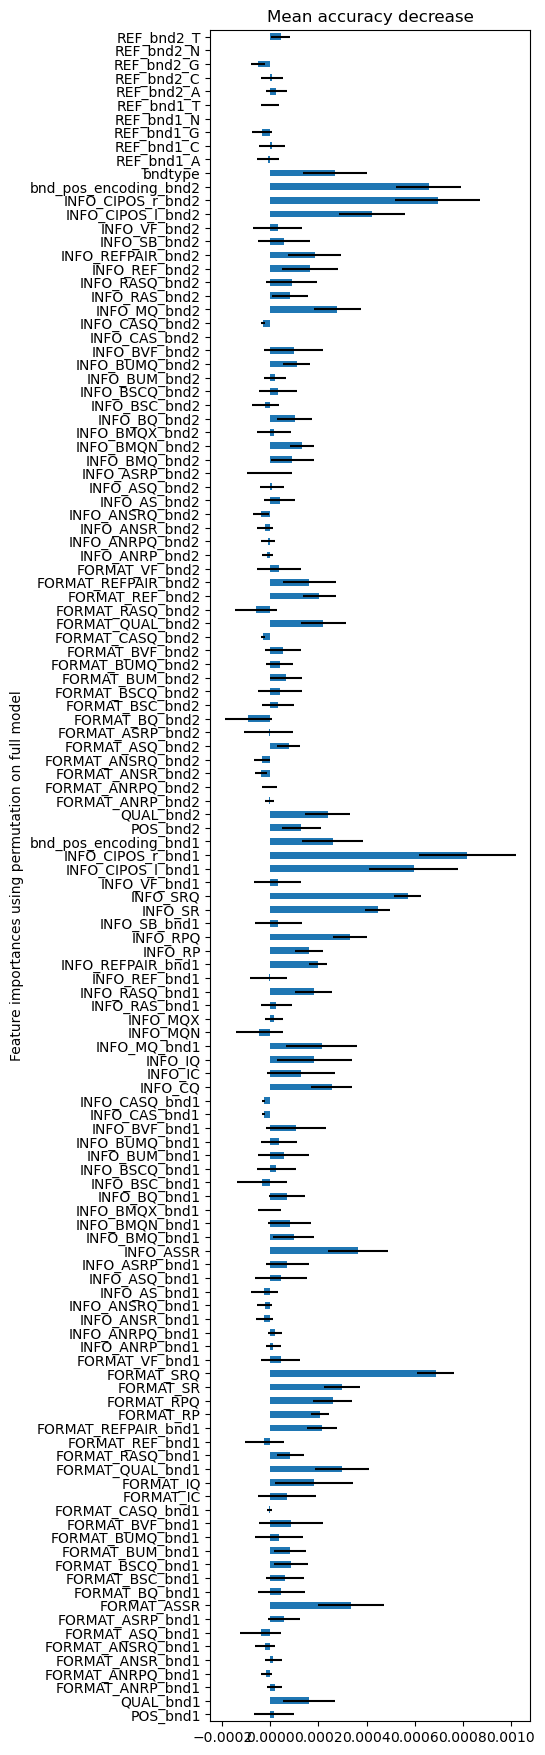

<Figure size 640x480 with 0 Axes>

In [15]:

fig, ax = plt.subplots()
forest_importances.plot(xerr=result.importances_std, ax=ax, kind='barh')
ax.set_title("Mean accuracy decrease")
ax.set_ylabel("Feature importances using permutation on full model")

fig.tight_layout()
fig.set_size_inches((5,20))
plt.show()
# plt.show()
plt.savefig('figs/featureimportance_perm.enoto.png')
# Save figure with estimated size to ensure text is readable


Elapsed time to compute the importances: 38.519 seconds


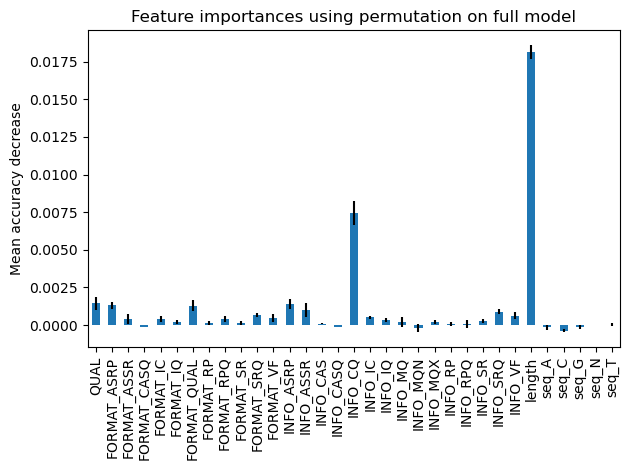

In [33]:
# I am not sure it is possible to do a custom loss function in sklearn - I DO NOT NEED TO, I CAN JUST USE WEIGHTS FOR DUPLESSIS CORRECTION
# So I implement Elkan and Noto sample weighting scheme
# Where unlabeled samples are split into 2:
# - positive part with weight (1 - label_freq) / label_freq * y_nontrad / (1 - y_nontrad)
# - negative part with weight 1 - positive_weight

In [18]:
y_proba_nontrad = RF_nontrad.predict_proba(X_train)
pos_weights = y_proba_nontrad[:, 1]
pos_weights[y_train] = 1

In [20]:
# We double the unlabeled part of X and y and give negative weights to it
X_train_neg = X_train[y_train == False]
y_train_neg = y_train[y_train == False]
neg_weights = y_proba_nontrad[y_train == False, 0]
X_doubled = pd.concat([X_train, X_train_neg])
y_doubled = np.concatenate([y_train, y_train_neg])
weights_doubled = np.concatenate([pos_weights, neg_weights])
RF_enoto = RF(
    max_features=int(np.sqrt(X.shape[1])), random_state=0, n_estimators=500
)
RF_enoto_fit = RF_enoto.fit(X_doubled, y_doubled, sample_weight=weights_doubled)

In [36]:
X_doubled

,QUAL,FORMAT_ASRP,FORMAT_ASSR,FORMAT_CASQ,FORMAT_IC,FORMAT_IQ,FORMAT_QUAL,FORMAT_RP,FORMAT_RPQ,FORMAT_SR,...,INFO_RPQ,INFO_SR,INFO_SRQ,INFO_VF,length,seq_A,seq_C,seq_G,seq_N,seq_T
ID,,,,,,,,,,,,,,,,,,,,,
gridss233fb_4470,1194.91,0,21,0.0,8,368.88,1194.91,0,0.00,0,...,0.00,0,0.00,13,23,True,False,False,False,False
gridss123fb_624,66.44,3,0,0.0,0,0.00,66.44,0,0.00,0,...,0.00,0,0.00,3,16,False,False,True,False,False
gridss76fb_242,294.98,10,0,0.0,0,0.00,294.98,9,136.42,0,...,136.42,0,0.00,10,539834,True,False,False,False,False
gridss187fb_1769,391.66,0,8,0.0,4,151.66,391.66,0,0.00,0,...,0.00,0,0.00,4,14,True,False,False,False,False
gridss195fb_4054,1115.98,0,25,0.0,5,278.21,1115.98,0,0.00,5,...,0.00,5,95.21,15,33,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
gridss247fb_2174,2694.69,0,56,0.0,27,887.62,2694.69,0,0.00,0,...,0.00,0,0.00,29,9,False,False,False,False,True
gridss153fb_6367,462.00,0,0,0.0,15,462.00,462.00,0,0.00,0,...,0.00,0,0.00,15,19,True,False,False,False,False
gridss108fb_21,5017.71,0,95,0.0,39,1580.30,5017.71,0,0.00,0,...,0.00,0,0.00,56,16,True,False,False,False,False


In [21]:
y_enoto = RF_enoto_fit.predict_proba(X)[:,1]

In [24]:
pd.DataFrame({
    'ID': callset_overlapped_df.index,
    'y_duplessis': y_duplessis,
    'y_enoto': y_enoto
}).to_csv('saved/y_duplessis_enoto_bps.csv', index=False)

In [22]:
# pd.Series(y_enoto).to_csv('saved/y_enoto.csv')
pd.Series(y_enoto).to_csv('saved/y_enoto_bps.csv')


In [38]:
from sklearn.inspection import permutation_importance

start_time = time.time()
result = permutation_importance(
    RF_enoto_fit, X_val, y_val, n_repeats=10, random_state=42, n_jobs=2
)
elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

forest_importances = pd.Series(result.importances_mean, index=X.columns)

Elapsed time to compute the importances: 37.467 seconds


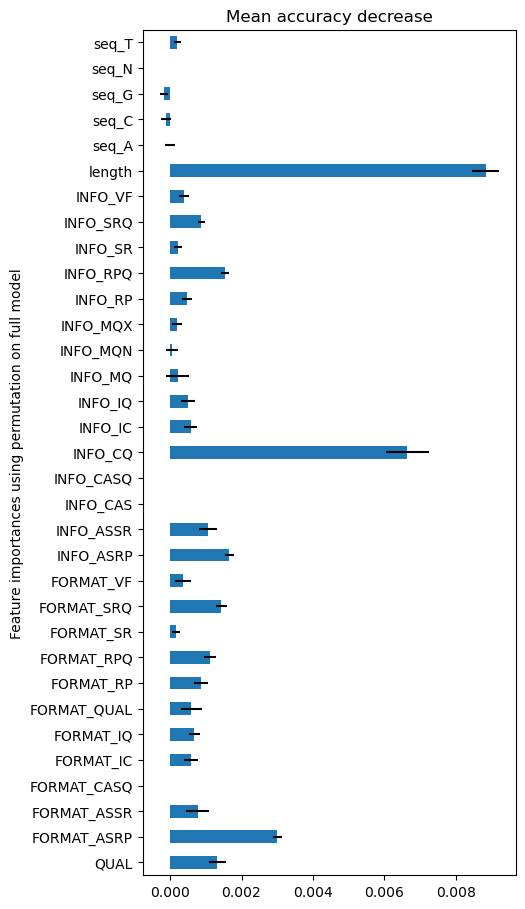

In [39]:

fig, ax = plt.subplots()
forest_importances.plot(xerr=result.importances_std, ax=ax, kind='barh')
ax.set_title("Mean accuracy decrease")
ax.set_ylabel("Feature importances using permutation on full model")

fig.tight_layout()
fig.set_size_inches((5,10))
plt.show()
# plt.show()
# plt.savefig('figs/featureimportance_perm.enoto.png')

In [52]:
disp = CalibrationDisplay(prob_true, prob_pred, y_prob)
disp.plot()

<Figure size 1000x600 with 0 Axes>